<a href="https://colab.research.google.com/github/shubham0109/langgraph-learning/blob/main/AIAgent3_ReAct.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install langchain-openai langchain-core langgraph python-dotenv
!pip install langchain-google-genai

  Using cached langchain_google_genai-4.4.2-py3-none-any.whl.metadata (2.7 kB)
  Using cached filetype-1.2.0-py2.py3-none-any.whl.metadata (6.5 kB)
  Using cached google_genai-2.31.0-py3-none-any.whl.metadata (58 kB)
  Using cached google_auth-2.62.0-py3-none-any.whl.metadata (6.0 kB)
Using cached langchain_google_genai-4.4.2-py3-none-any.whl (81 kB)
Using cached filetype-1.2.0-py2.py3-none-any.whl (19 kB)
Using cached google_genai-2.31.0-py3-none-any.whl (1.2 MB)
Using cached google_auth-2.62.0-py3-none-any.whl (267 kB)
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.49.0
    Uninstalling google-auth-2.49.0:
      Successfully uninstalled google-auth-2.49.0
  Attempting uninstall: google-genai
    Found existing installation: google-genai 2.12.1
    Uninstalling google-genai-2.12.1:
      Successfully uninstalled google-genai-2.12.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behavio

In [1]:
from typing import Annotated, Sequence, TypedDict
from dotenv import load_dotenv
from langchain_core.messages import BaseMessage # The foundational class for all message types in LangGraph
from langchain_core.messages import ToolMessage # Passes data back to LLM after it calls a tool such as the content and the tool_call_id
from langchain_core.messages import SystemMessage # Message for providing instructions to the LLM
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import ToolNode
from langchain_google_genai import ChatGoogleGenerativeAI

In [2]:
# Annotated - provides additional context without affecting the type itself

In [5]:
class AgentState(TypedDict):
  messages: Annotated[Sequence[BaseMessage], add_messages]

In [38]:
@tool
def add_tool(a: int, b: int):
  """This is an addition function that adds 2 numbers together"""
  return a+b

@tool
def subtract_tool(a: int, b: int):
    """Subtraction function"""
    return a - b

@tool
def multiply_tool(a: int, b: int):
    """Multiplication function"""
    return a * b

tools = [add_tool, subtract_tool, multiply_tool]

In [39]:
import os
from getpass import getpass

# Securely load the Google Gemini API key
gemini_api_key = os.environ.get("GEMINI_API_KEY")

if not gemini_api_key:
    try:
        from google.colab import userdata
        gemini_api_key = userdata.get('GEMINI_API_KEY')
    except Exception:
        gemini_api_key = getpass("Enter your Gemini API Key (from Google AI Studio): ")

os.environ["GEMINI_API_KEY"] = gemini_api_key

# Initialize the free Gemini 2.5 Flash model
model = ChatGoogleGenerativeAI(model="gemini-3.8-flash", google_api_key=gemini_api_key).bind_tools(tools)

In [47]:
def model_call_node(state: AgentState) -> AgentState:
  system_prompt = SystemMessage(content="You are my AI assistant, please answer my query to the best of your ability")
  response = model.invoke([system_prompt] + state["messages"])
  return {"messages": [response]}

In [48]:
def should_continue(state: AgentState) -> AgentState:
  messages = state["messages"]
  last_message = messages[-1]
  print("TOOL CALLS")
  print(last_message.tool_calls)
  if not last_message.tool_calls:
    return "end"
  else:
    return "continue"

In [50]:
graph = StateGraph(AgentState)
graph.add_node("model_call_node", model_call_node)
tool_node = ToolNode(tools)
graph.add_node("tool_node", tool_node)

graph.set_entry_point("model_call_node")
graph.add_conditional_edges(
    "model_call_node",
    should_continue,
    {
        "continue": "tool_node",
        "end": END
    }
)

graph.add_edge("tool_node", "model_call_node")

agent = graph.compile()

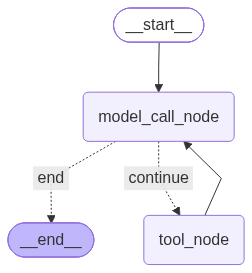

In [51]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [52]:
def print_stream(stream):
    for s in stream:
        message = s["messages"][-1]
        if isinstance(message, tuple):
            print(message)
        else:
            message.pretty_print()

inputs = {"messages": [("user", "Add 40 + 12 and then multiply the result by 6. And then subtract 5. And then divide by 3. Also tell me a joke please.")]}
print_stream(agent.stream(inputs, stream_mode="values"))

================================ Human Message =================================

Add 40 + 12 and then multiply the result by 6. And then subtract 5. And then divide by 3. Also tell me a joke please.
TOOL CALLS
[{'name': 'add_tool', 'args': {'a': 40, 'b': 12}, 'id': 'call_1862407', 'type': 'tool_call'}]
================================== Ai Message ==================================

[]
Tool Calls:
  add_tool (call_1862407)
 Call ID: call_1862407
  Args:
    a: 40
    b: 12
================================= Tool Message =================================
Name: add_tool

52
TOOL CALLS
[{'name': 'multiply_tool', 'args': {'b': 6, 'a': 52}, 'id': 'call_46568', 'type': 'tool_call'}]
================================== Ai Message ==================================

[]
Tool Calls:
  multiply_tool (call_46568)
 Call ID: call_46568
  Args:
    b: 6
    a: 52
================================= Tool Message =================================
Name: multiply_tool

312
TOOL CALLS
[{'name': 'subtract_too